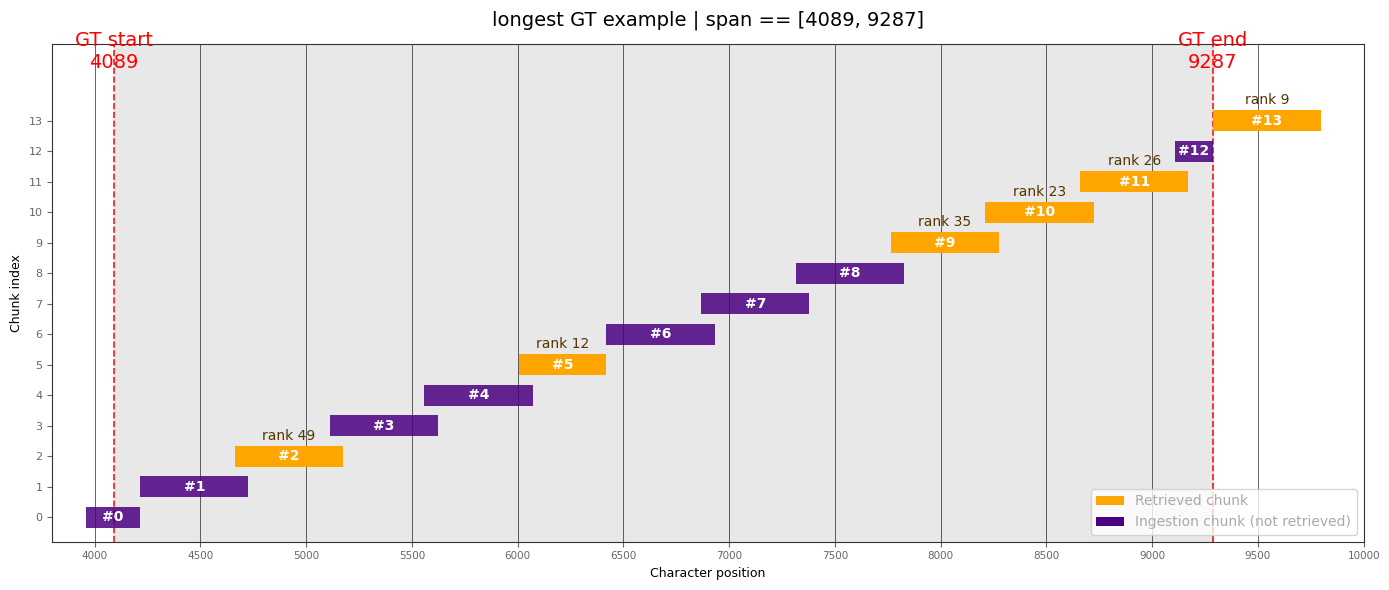

In [22]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

gt_start = 4089
gt_end = 9287

ingestion_chunks = [
    {'idx': 0,  'char_start': 3959, 'char_end': 4215},
    {'idx': 1,  'char_start': 4215, 'char_end': 4727},
    {'idx': 2,  'char_start': 4663, 'char_end': 5175},
    {'idx': 3,  'char_start': 5111, 'char_end': 5623},
    {'idx': 4,  'char_start': 5559, 'char_end': 6071},
    {'idx': 5,  'char_start': 6007, 'char_end': 6419},
    {'idx': 6,  'char_start': 6419, 'char_end': 6931},
    {'idx': 7,  'char_start': 6867, 'char_end': 7379},
    {'idx': 8,  'char_start': 7315, 'char_end': 7827},
    {'idx': 9,  'char_start': 7763, 'char_end': 8275},
    {'idx': 10, 'char_start': 8211, 'char_end': 8723},
    {'idx': 11, 'char_start': 8659, 'char_end': 9171},
    {'idx': 12, 'char_start': 9107, 'char_end': 9286},
    {'idx': 13, 'char_start': 9286, 'char_end': 9798},
]

# Maps char_start -> retrieval rank
retrieved_by_start = {
    9286: 9,
    6007: 12,
    8211: 23,
    8659: 26,
    7763: 35,
    4663: 49,
}

fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor("#ffffff")
ax.set_facecolor("#ffffff")

# GT span shaded region
ax.axvspan(gt_start, gt_end, ymin=0, ymax=1, color='lightgrey', alpha=0.5, zorder=0)
ax.axvline(gt_start, color='red', linewidth=1.2, linestyle='--', alpha=0.9, zorder=1)
ax.axvline(gt_end,   color ='red', linewidth=1.2, linestyle='--', alpha=0.9, zorder=1)

ax.text(gt_start, 14.6, 'GT start\n4089', color='red', fontsize=14, ha='center', va='bottom')
ax.text(gt_end,   14.6, 'GT end\n9287',  color='red', fontsize=14, ha='center', va='bottom')

for chunk in ingestion_chunks:
    idx = chunk['idx']
    s, e = chunk['char_start'], chunk['char_end']
    is_retrieved = s in retrieved_by_start

    facecolor = 'orange' if is_retrieved else 'indigo'
    lw = 1.5 if is_retrieved else 0.8
    alpha = 1.0 if is_retrieved else 0.85
    zorder = 3 if is_retrieved else 2

    ax.barh(idx, e - s, left=s, height=0.7,
            color=facecolor, linewidth=lw,
            alpha=alpha, zorder=zorder)

    mid = (s + e) / 2
    ax.text(mid, idx, f'#{idx}', color='white', fontsize=10,
            ha='center', va='center', fontweight='bold', zorder=4)

    if is_retrieved:
        rank = retrieved_by_start[s]
        ax.text(mid, idx + 0.45, f'rank {rank}', color="#563400",
                fontsize=10, ha='center', va='bottom', zorder=5)

ax.set_xlim(3800, 10000)
ax.set_ylim(-0.8, 15.5)
ax.set_xlabel('Character position', fontsize=9)
ax.set_ylabel('Chunk index', fontsize=9)
ax.set_title('longest GT example | span == [4089, 9287]',
             color='black', fontsize=14, pad=14)

ax.tick_params(colors='#666', labelsize=8)
for spine in ax.spines.values():
    spine.set_edgecolor('#333')

ax.set_yticks(range(14))
ax.set_xticks(range(4000, 10001, 500))
ax.set_xticklabels([str(x) for x in range(4000, 10001, 500)], fontsize=7.5)
ax.set_yticklabels([str(i) for i in range(14)], fontsize=8)
ax.grid(axis='x', color='#222', linewidth=0.5, zorder=0)

retrieved_patch = mpatches.Patch(facecolor="orange", label='Retrieved chunk')
ingestion_patch = mpatches.Patch(facecolor="indigo", label='Ingestion chunk (not retrieved)')
#gt_patch        = mpatches.Patch(facecolor="grey", label='Ground truth span')
ax.legend(handles=[retrieved_patch, ingestion_patch],
          loc='lower right', fontsize=10, labelcolor='#aaa')

plt.tight_layout()
plt.savefig('GT 14 Chunks example.png', dpi=300)
